In [1]:
# Cell 1: Install required packages
%pip install -q pandas numpy matplotlib seaborn scikit-learn imbalanced-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
# Cell 2: Import libraries

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    RandomizedSearchCV
)

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline as SklearnPipeline
from imblearn.pipeline import Pipeline as ImbPipeline

from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    RandomForestRegressor,
    VotingClassifier,
    AdaBoostClassifier,
    HistGradientBoostingClassifier
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

RANDOM_STATE = 42

sns.set_theme(style="whitegrid")

print("All libraries imported successfully.")

All libraries imported successfully.


In [3]:
# Cell 3: Load dataset

df = pd.read_csv("fiverr_data.csv")

print("Dataset shape:", df.shape)

display(df.head())

print("\nDataset information:")
df.info()

print("\nDescriptive statistics:")
display(df.describe().T)

print("\nColumn names:")
print(df.columns.tolist())

Dataset shape: (458798, 53)


,label,user_id,X1,X2,X3,X4,X5,X6,X7,X8,...,X42,X43,X44,X45,X46,X47,X48,X49,X50,X51
0,0,1,20972,14,13,3,11,1,2,15,...,0,0,0,0,0,0,0,0,1,0
1,0,2,7362,213,71,3,11,1,2,15,...,0,0,0,0,0,0,0,0,0,0
2,0,3,21216,215,71,3,11,1,2,15,...,0,0,0,0,0,0,0,0,0,0
3,0,4,2261,212,71,2,8,1,2,15,...,0,0,0,0,0,0,0,1,0,0
4,0,5,4543,213,71,2,8,1,2,15,...,0,0,0,0,0,0,0,0,0,0



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 458798 entries, 0 to 458797
Data columns (total 53 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   label    458798 non-null  int64  
 1   user_id  458798 non-null  int64  
 2   X1       458798 non-null  int64  
 3   X2       458798 non-null  int64  
 4   X3       458798 non-null  int64  
 5   X4       458798 non-null  int64  
 6   X5       458798 non-null  int64  
 7   X6       458798 non-null  int64  
 8   X7       458798 non-null  int64  
 9   X8       458798 non-null  int64  
 10  X9       458798 non-null  int64  
 11  X10      458798 non-null  int64  
 12  X11      458798 non-null  int64  
 13  X12      458798 non-null  int64  
 14  X13      458792 non-null  float64
 15  X14      458798 non-null  int64  
 16  X15      458798 non-null  int64  
 17  X16      458798 non-null  int64  
 18  X17      458798 non-null  int64  
 19  X18      458798 non-null  int64  
 20  X19 

,count,mean,std,min,25%,50%,75%,max
label,458798.0,0.026855,0.161660,0.0,0.00,0.0,0.00,1.0
user_id,458798.0,241363.771411,139440.017203,1.0,120595.25,241234.5,362157.75,482935.0
X1,458798.0,10850.591243,7078.656632,1.0,4692.00,11574.0,16425.00,24234.0
X2,458798.0,154.947696,67.952267,1.0,95.00,189.0,213.00,222.0
X3,458798.0,28.107965,19.227303,1.0,13.00,14.0,37.00,94.0
X4,458798.0,2.407831,0.800163,1.0,2.00,3.0,3.00,3.0
X5,458798.0,10.985176,5.527487,1.0,8.00,11.0,16.00,17.0
X6,458798.0,3.215446,0.811902,1.0,3.00,3.0,4.00,4.0
X7,458798.0,5.082675,3.302548,1.0,2.00,5.0,8.00,11.0
X8,458798.0,15.654039,4.993260,1.0,14.00,15.0,21.00,29.0



Column names:
['label', 'user_id', 'X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'X9', 'X10', 'X11', 'X12', 'X13', 'X14', 'X15', 'X16', 'X17', 'X18', 'X19', 'X20', 'X21', 'X22', 'X23', 'X24', 'X25', 'X26', 'X27', 'X28', 'X29', 'X30', 'X31', 'X32', 'X33', 'X34', 'X35', 'X36', 'X37', 'X38', 'X39', 'X40', 'X41', 'X42', 'X43', 'X44', 'X45', 'X46', 'X47', 'X48', 'X49', 'X50', 'X51']


In [4]:
# Cell 4: Data quality checks

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nMissing values per column:")
missing = df.isnull().sum()
display(missing[missing > 0].sort_values(ascending=False))

print("\nNumber of duplicate rows:", df.duplicated().sum())

print("\nData types:")
display(df.dtypes.value_counts())

print("\nUnique values per column:")
display(df.nunique().sort_values())

Rows: 458798
Columns: 53

Missing values per column:


X13    6
dtype: int64


Number of duplicate rows: 0

Data types:


int64      52
float64     1
Name: count, dtype: int64


Unique values per column:


X27             1
X29             1
X30             1
X33             1
X47             1
X48             1
X46             1
label           2
X51             2
X45             2
X49             2
X50             2
X20             2
X12             2
X11             2
X4              3
X6              4
X14             6
X37             6
X40             7
X36             9
X13            10
X35            11
X7             11
X34            12
X15            13
X43            16
X23            16
X5             17
X38            23
X41            25
X18            25
X17            27
X39            29
X28            29
X44            29
X8             29
X24            30
X16            35
X31            36
X9             38
X26            41
X42            51
X22            54
X32            71
X25            84
X3             94
X19           200
X2            222
X21           511
X1          23696
X10         47380
user_id    458798
dtype: int64

Class counts:


label
0    446477
1     12321
Name: count, dtype: int64


Class percentages:


label
0    97.315
1     2.685
Name: proportion, dtype: float64

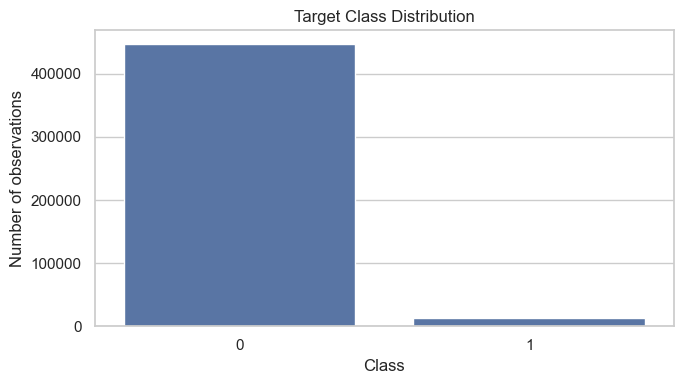

In [5]:
# Cell 5: Class distribution

target = "label"

if target not in df.columns:
    raise ValueError("Target column 'label' was not found.")

print("Class counts:")
display(df[target].value_counts().sort_index())

print("\nClass percentages:")
display(
    (df[target].value_counts(normalize=True) * 100)
    .sort_index()
    .round(3)
)

plt.figure(figsize=(7, 4))
sns.countplot(data=df, x=target)
plt.title("Target Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of observations")
plt.tight_layout()
plt.show()

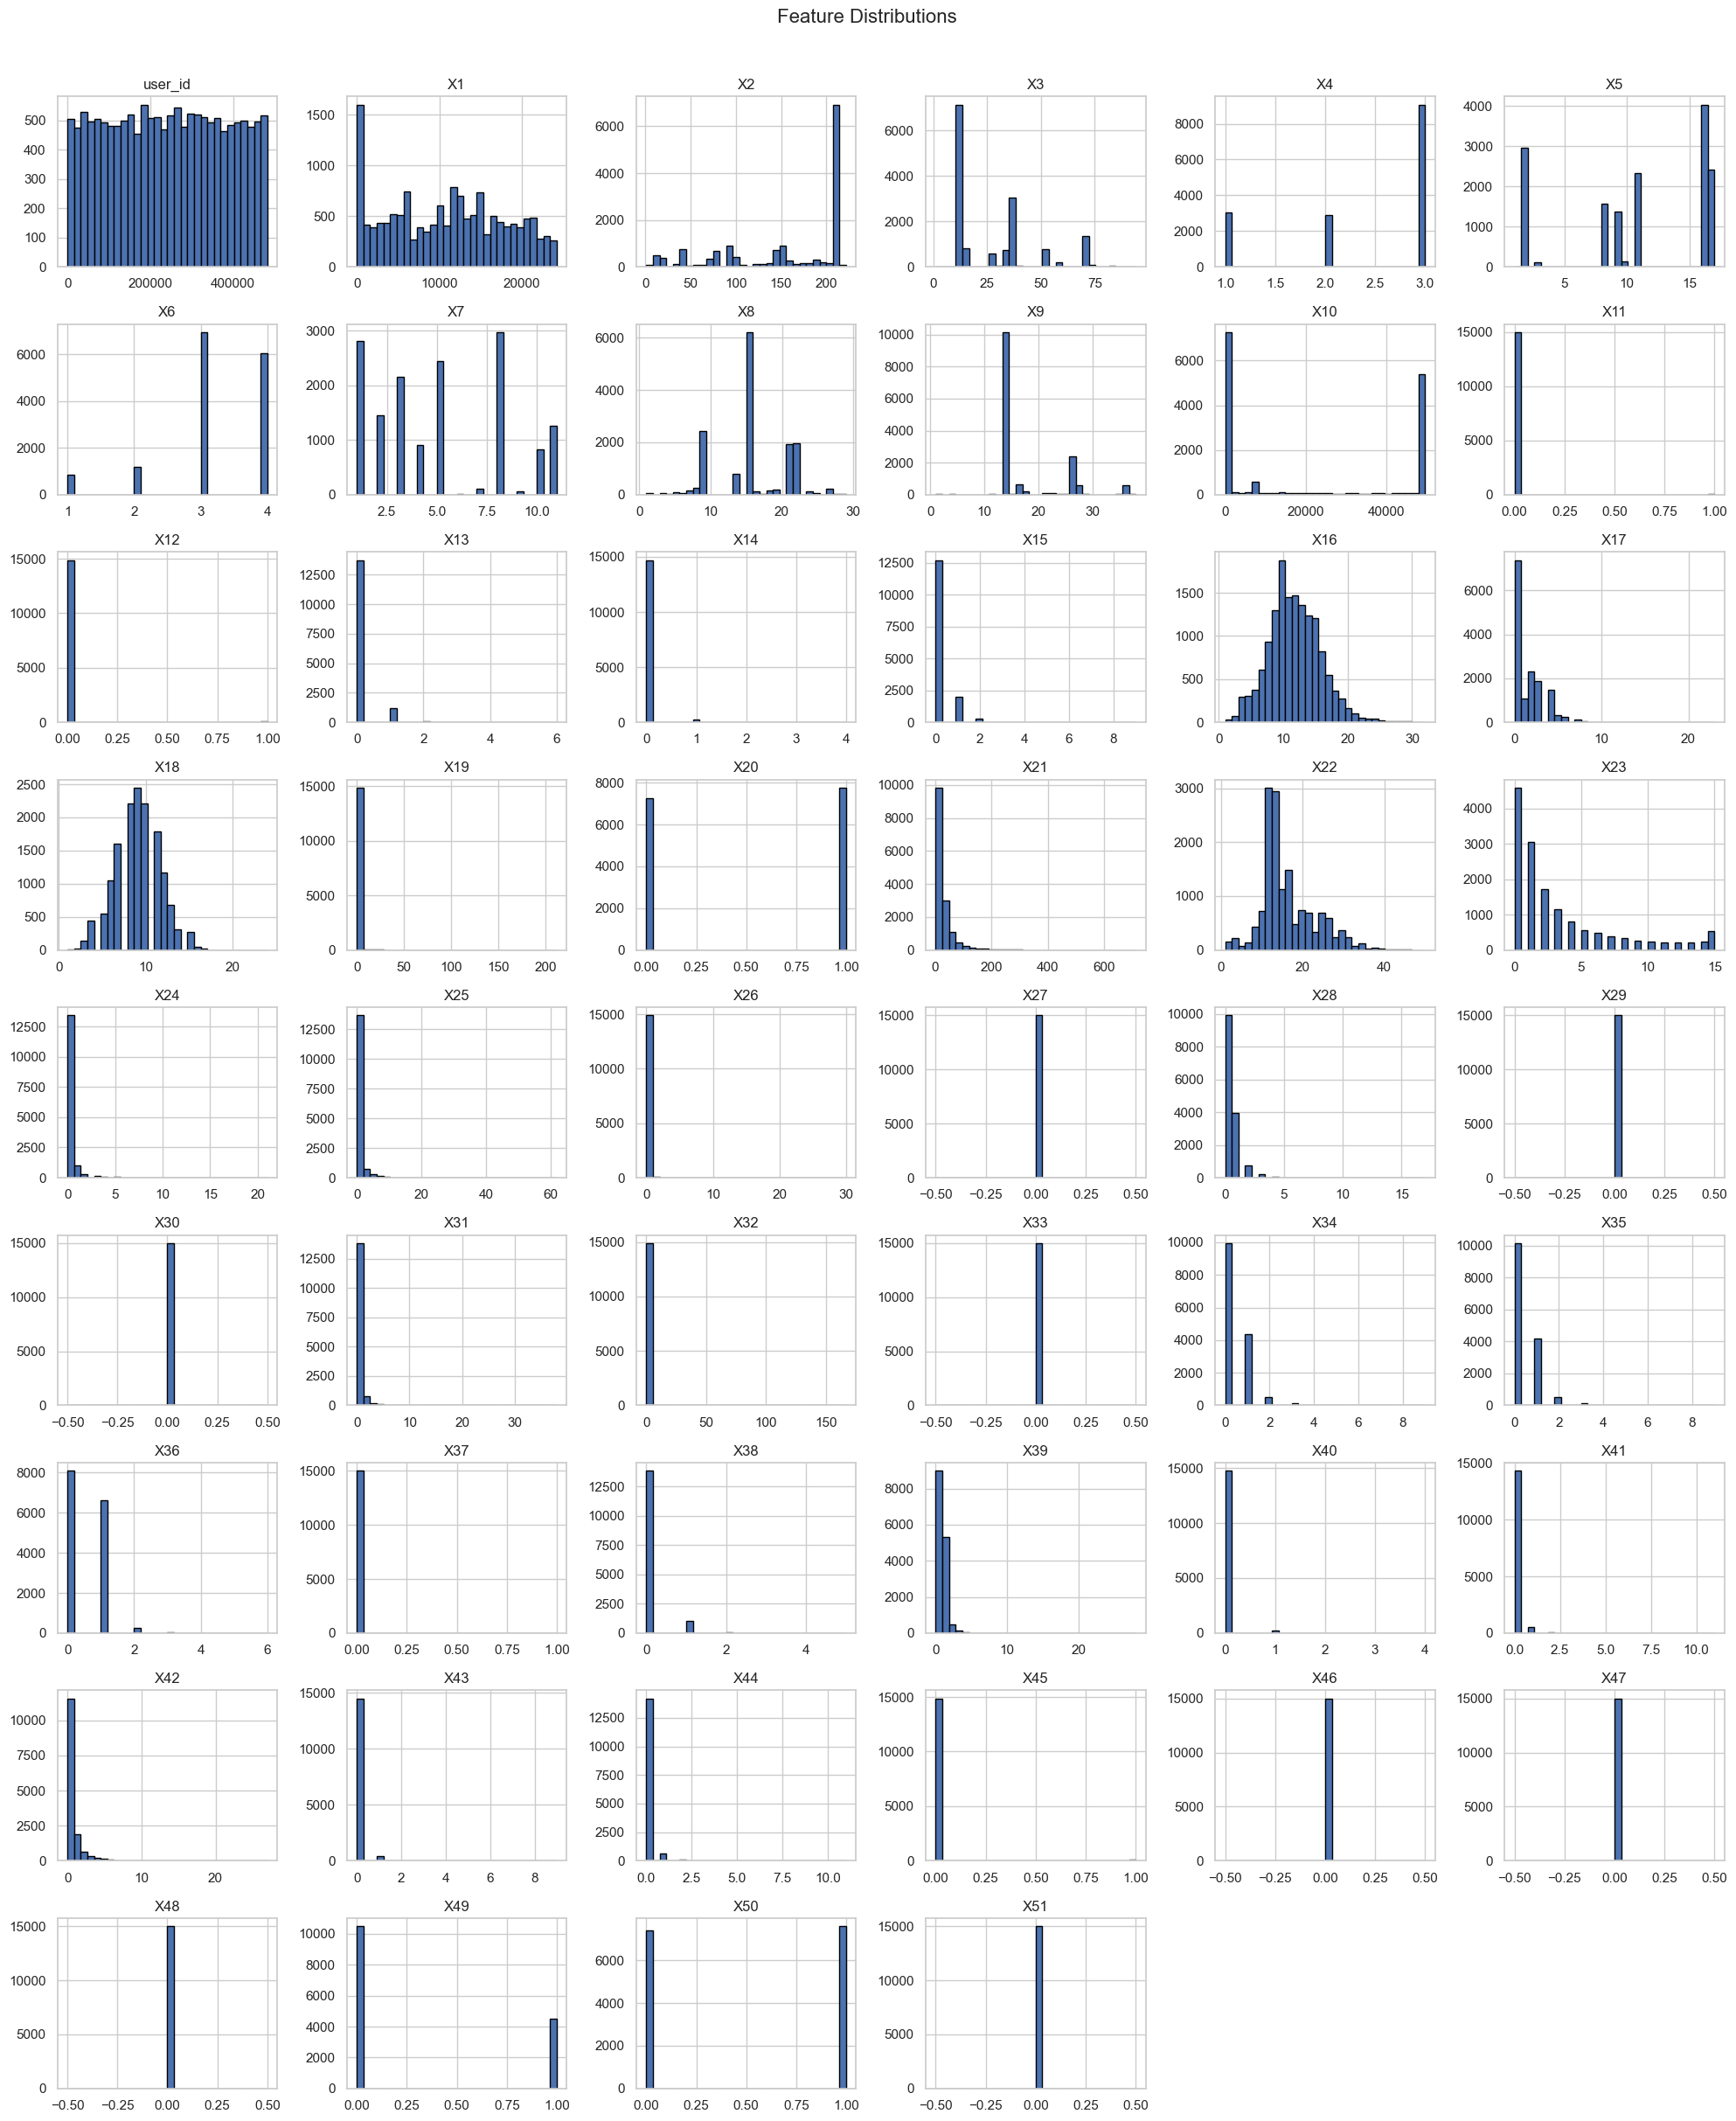

In [6]:
# Cell 6: Histograms

numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
feature_cols = [c for c in numeric_cols if c != target]

plot_sample = df.sample(
    n=min(15000, len(df)),
    random_state=RANDOM_STATE
)

plot_sample[feature_cols].hist(
    bins=30,
    figsize=(20, 24),
    layout=(9, 6),
    edgecolor="black"
)

plt.suptitle("Feature Distributions", y=1.01, fontsize=16)
plt.tight_layout()
plt.show()

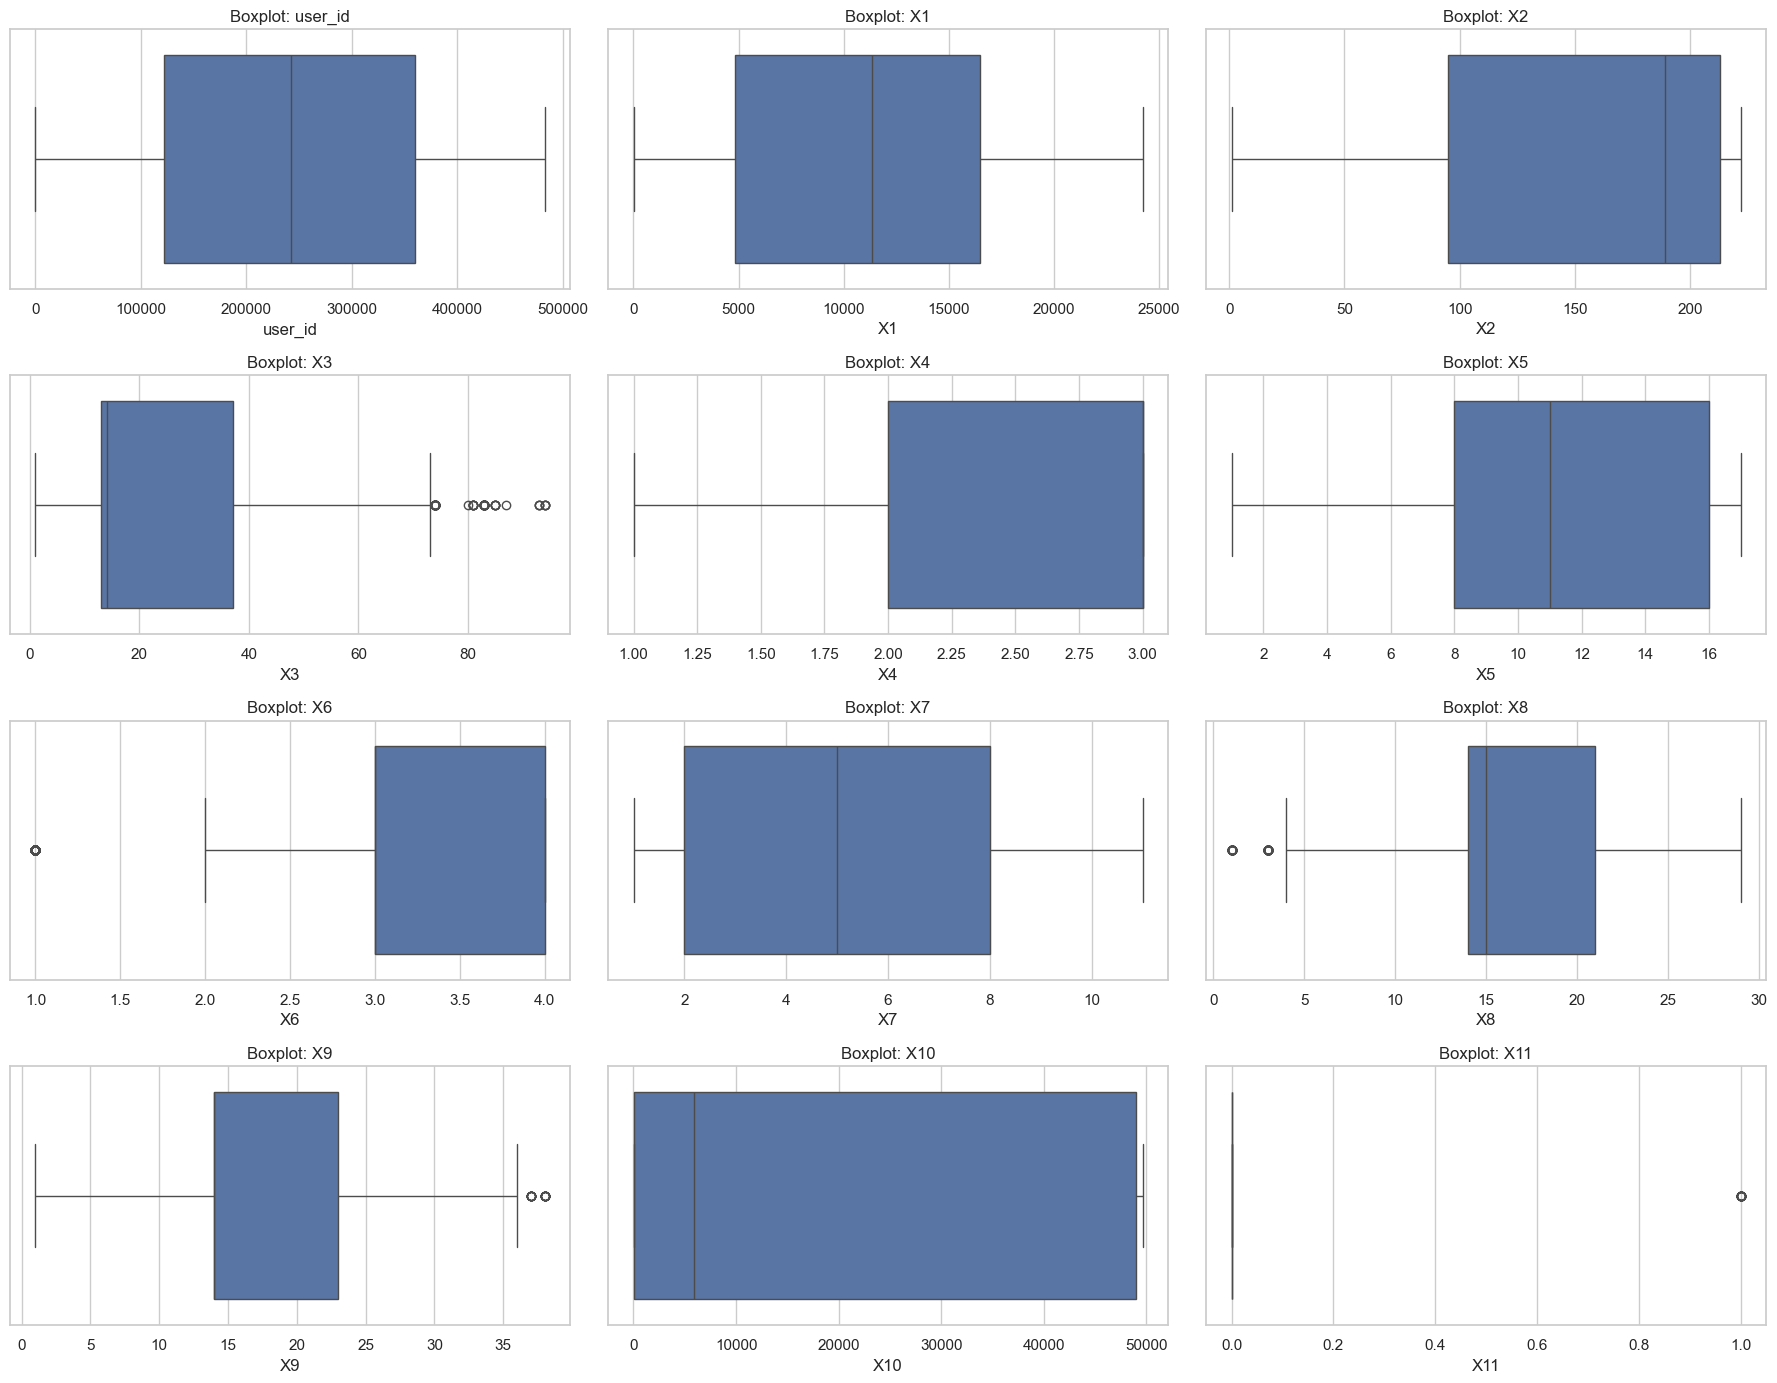

In [7]:
# Cell 7: Boxplots

box_cols = feature_cols[:12]  # Start with 12 features

fig, axes = plt.subplots(4, 3, figsize=(18, 14))
axes = axes.flatten()

for i, col in enumerate(box_cols):
    sns.boxplot(
        x=plot_sample[col],
        ax=axes[i]
    )
    axes[i].set_title(f"Boxplot: {col}")

for j in range(len(box_cols), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

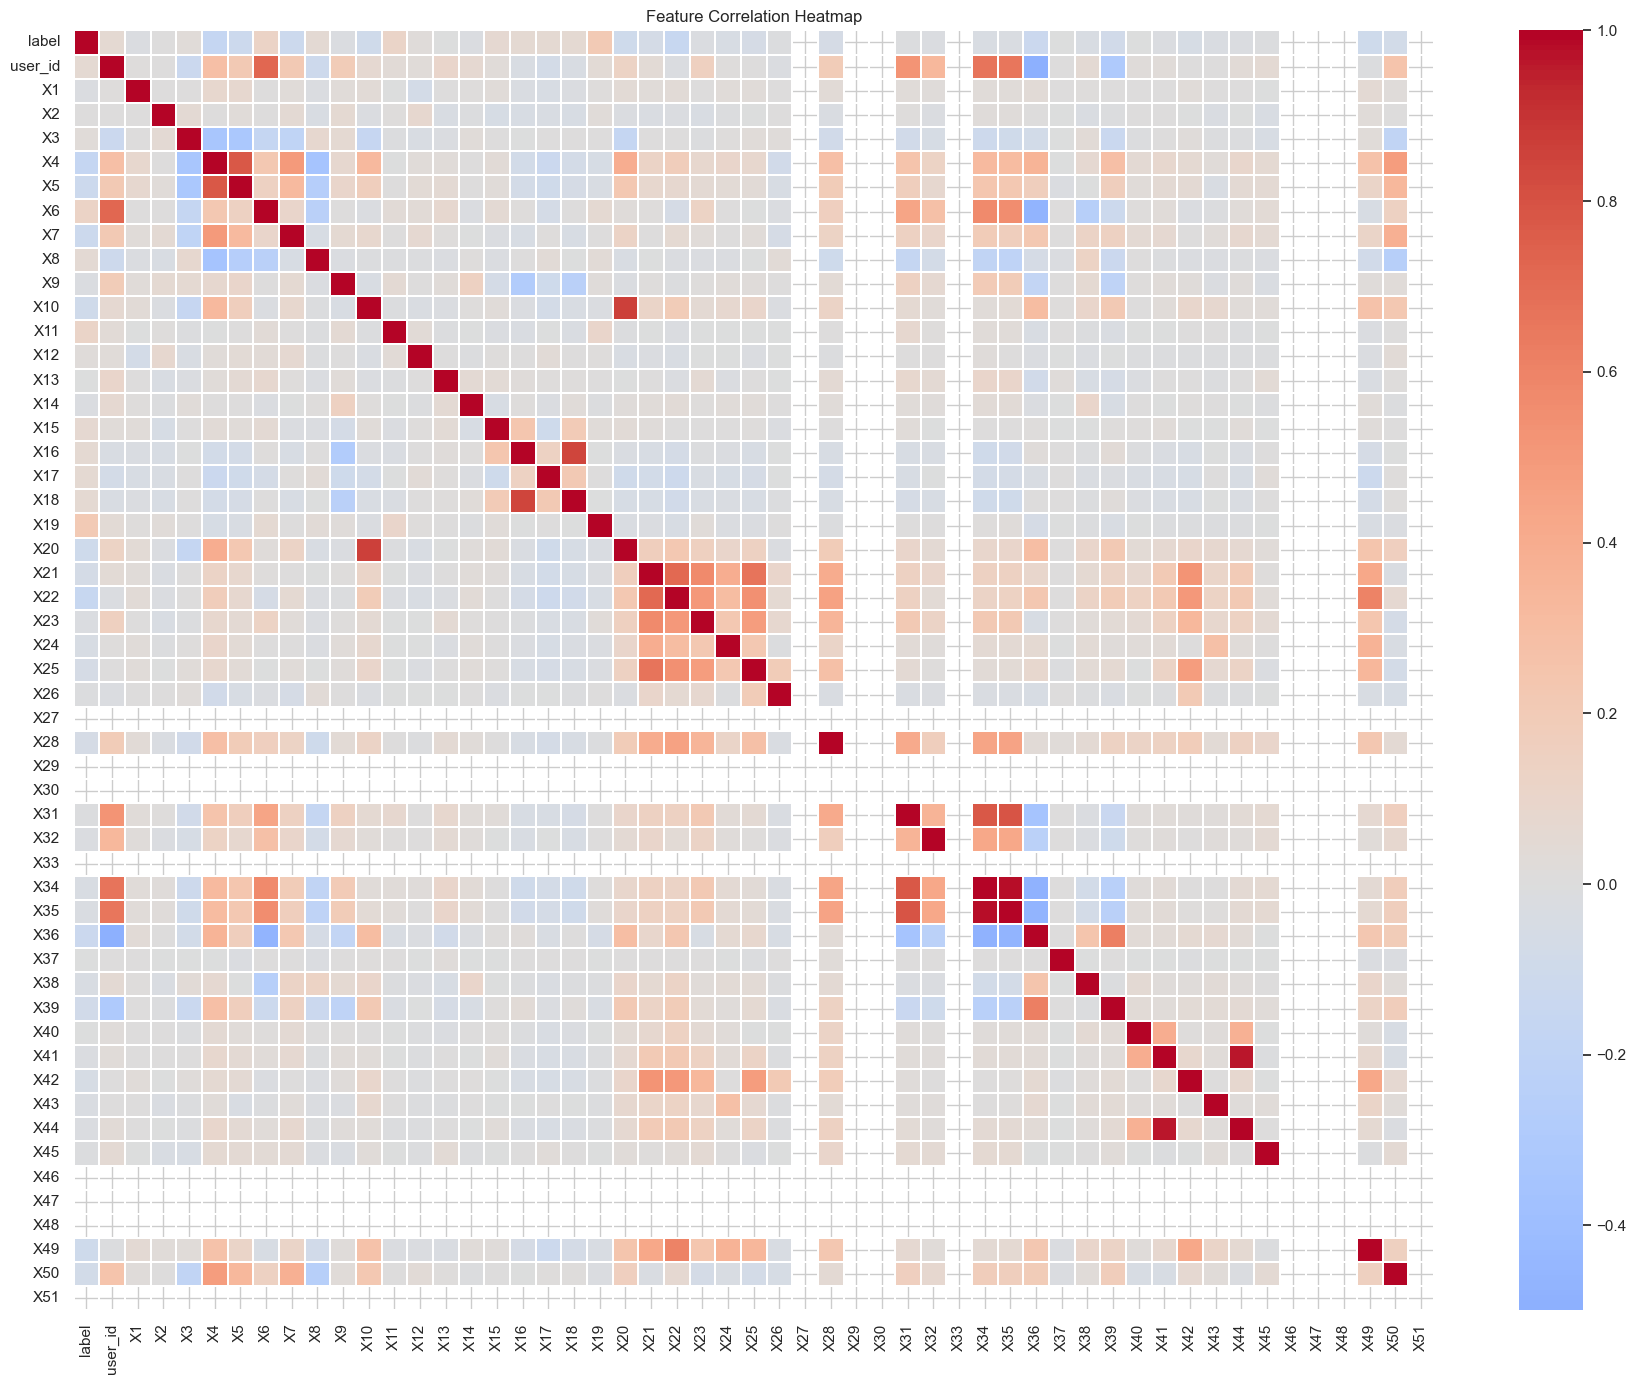

In [8]:
# Cell 8: Correlation heatmap

corr = plot_sample[numeric_cols].corr()

plt.figure(figsize=(18, 14))
sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0,
    linewidths=0.1
)

plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

Features selected for pairplot: ['X19', 'X4', 'X22', 'X36', 'X5']


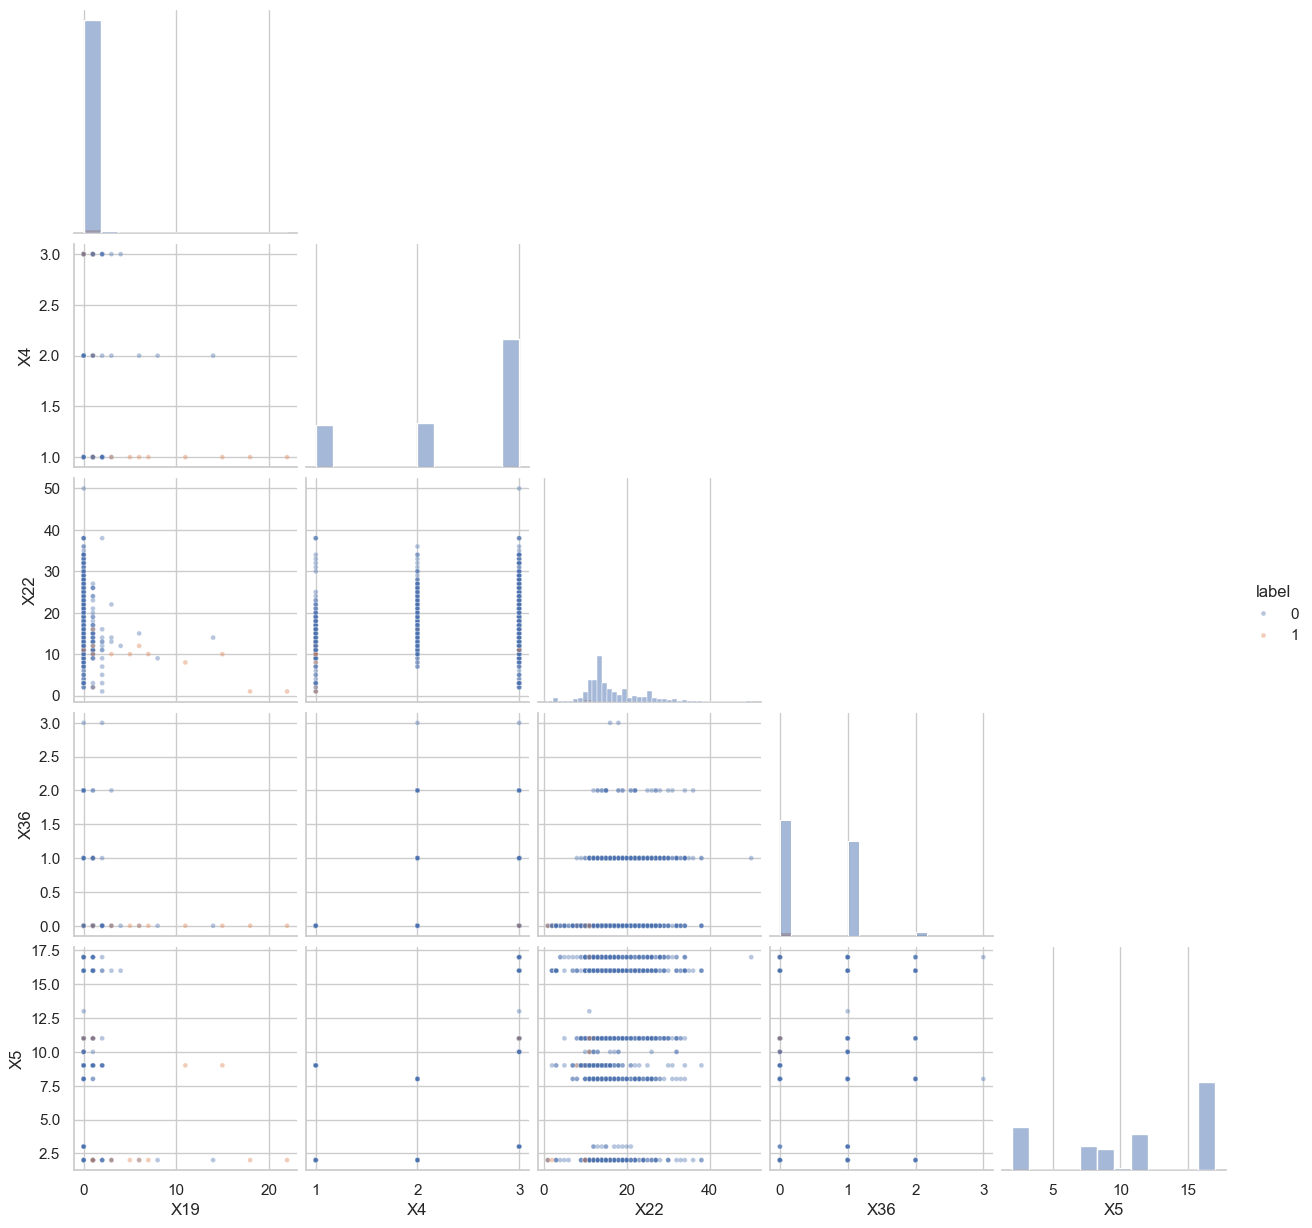

In [9]:
# Cell 9: Pairplot on a small sample

target_corr = (
    corr[target]
    .drop(target)
    .abs()
    .sort_values(ascending=False)
)

pair_features = target_corr.head(5).index.tolist()

print("Features selected for pairplot:", pair_features)

pair_data = df[pair_features + [target]].sample(
    n=min(1500, len(df)),
    random_state=RANDOM_STATE
)

sns.pairplot(
    pair_data,
    vars=pair_features,
    hue=target,
    corner=True,
    diag_kind="hist",
    plot_kws={"alpha": 0.4, "s": 12}
)

plt.show()

In [10]:
# Cell 10: Automated EDA summary

print("EDA SUMMARY")
print("=" * 60)

print(f"Number of rows: {df.shape[0]:,}")
print(f"Number of columns: {df.shape[1]}")

print(f"\nMissing values: {df.isnull().sum().sum():,}")
print(f"Duplicate rows: {df.duplicated().sum():,}")

print("\nTarget distribution:")
for cls, count in df[target].value_counts().sort_index().items():
    pct = 100 * count / len(df)
    print(f"Class {cls}: {count:,} rows ({pct:.2f}%)")

print("\nFeatures most correlated with target:")
display(target_corr.head(10).to_frame("absolute_correlation"))

EDA SUMMARY
Number of rows: 458,798
Number of columns: 53

Missing values: 6
Duplicate rows: 0

Target distribution:
Class 0: 446,477 rows (97.31%)
Class 1: 12,321 rows (2.69%)

Features most correlated with target:


,absolute_correlation
X19,0.206673
X4,0.162277
X22,0.151087
X36,0.126545
X5,0.120614
X6,0.118107
X11,0.114349
X7,0.113012
X20,0.104641
X49,0.102819


In [11]:
# Cell 11: IQR outlier report

outlier_rows = []

for col in feature_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    count = ((df[col] < lower) | (df[col] > upper)).sum()

    outlier_rows.append({
        "Feature": col,
        "Lower_Bound": lower,
        "Upper_Bound": upper,
        "Outlier_Count": count,
        "Outlier_Percentage": 100 * count / len(df)
    })

outlier_report = pd.DataFrame(outlier_rows)
outlier_report = outlier_report.sort_values(
    "Outlier_Percentage",
    ascending=False
)

display(outlier_report.head(20))

,Feature,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Percentage
42,X42,0.0,0.0,104728,22.826603
15,X15,0.0,0.0,69864,15.227617
24,X24,0.0,0.0,48682,10.610770
21,X21,-15.5,60.5,45569,9.932258
23,X23,-6.0,10.0,43139,9.402613
25,X25,-1.5,2.5,42618,9.289055
13,X13,0.0,0.0,37014,8.067603
38,X38,0.0,0.0,34706,7.564549
19,X19,0.0,0.0,29225,6.369906
6,X6,1.5,5.5,26053,5.678534


,Skewness
X37,118.699169
X51,117.898518
X25,91.244233
X26,49.156315
X32,42.162578
X19,30.408671
X31,29.423040
X44,24.140470
X11,23.532937
X41,20.606987


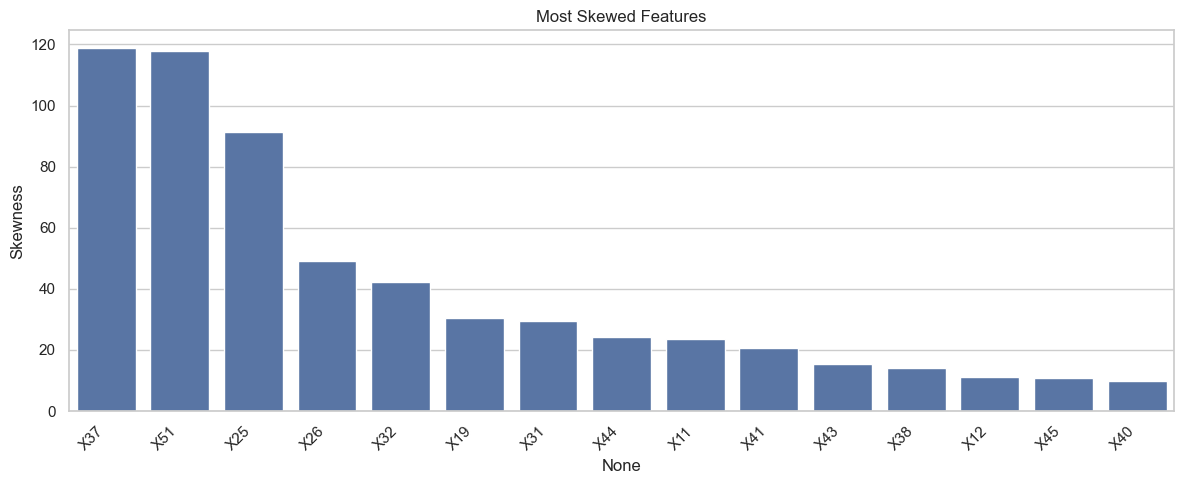

In [12]:
# Cell 12: Feature skewness

skewness = df[feature_cols].skew().sort_values(
    key=lambda x: x.abs(),
    ascending=False
)

display(skewness.head(20).to_frame("Skewness"))

plt.figure(figsize=(12, 5))
sns.barplot(
    x=skewness.head(15).index,
    y=skewness.head(15).values
)
plt.xticks(rotation=45, ha="right")
plt.title("Most Skewed Features")
plt.ylabel("Skewness")
plt.tight_layout()
plt.show()

In [13]:
# Cell 13: Prepare features and target

target = "label"

# Exclude target and unique identifier from predictors
drop_cols = [target]

if "user_id" in df.columns:
    drop_cols.append("user_id")

X = df.drop(columns=drop_cols).copy()
y = df[target].copy()

# Keep numerical predictors for this dataset
X = X.select_dtypes(include=np.number)

# Remove any columns that contain no information
constant_cols = X.columns[X.nunique(dropna=False) <= 1].tolist()

if constant_cols:
    print("Removing constant columns:", constant_cols)
    X = X.drop(columns=constant_cols)

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("Target classes:", sorted(y.dropna().unique()))

Removing constant columns: ['X27', 'X29', 'X30', 'X33', 'X46', 'X47', 'X48']
Feature matrix shape: (458798, 44)
Target shape: (458798,)
Target classes: [np.int64(0), np.int64(1)]


In [14]:
# Cell 14: Stratified train/test split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("\nTraining class distribution:")
display(
    pd.DataFrame({
        "Count": y_train.value_counts(),
        "Percentage": y_train.value_counts(normalize=True) * 100
    }).sort_index()
)

print("\nTesting class distribution:")
display(
    pd.DataFrame({
        "Count": y_test.value_counts(),
        "Percentage": y_test.value_counts(normalize=True) * 100
    }).sort_index()
)

Training shape: (367038, 44)
Testing shape: (91760, 44)

Training class distribution:


,Count,Percentage
label,,
0,357181,97.314447
1,9857,2.685553



Testing class distribution:


,Count,Percentage
label,,
0,89296,97.314734
1,2464,2.685266


In [15]:
# Cell 15: Preprocessing pipeline

def make_preprocessor(scale=True):
    steps = [
        ("imputer", SimpleImputer(strategy="median"))
    ]

    if scale:
        steps.append(("scaler", StandardScaler()))

    return SklearnPipeline(steps)

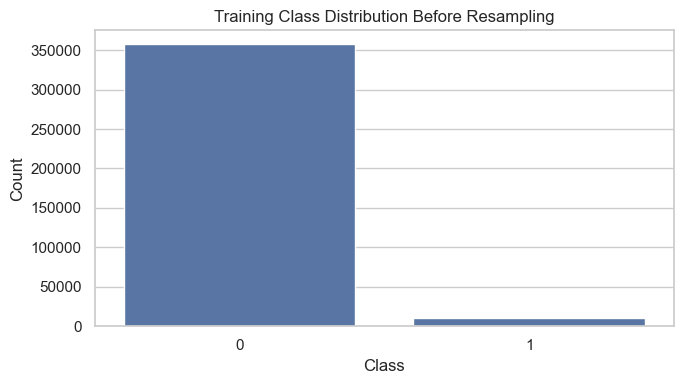

In [16]:
# Cell 16: Training imbalance

plt.figure(figsize=(7, 4))
sns.countplot(x=y_train)
plt.title("Training Class Distribution Before Resampling")
plt.xlabel("Class")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

In [17]:
# Cell 17: Compare sampling techniques

print("Original training distribution:")
print(y_train.value_counts().sort_index())

# Random oversampling
ros_demo = RandomOverSampler(random_state=RANDOM_STATE)
X_ros, y_ros = ros_demo.fit_resample(X_train, y_train)

print("\nAfter random oversampling:")
print(pd.Series(y_ros).value_counts().sort_index())

# Random undersampling
rus_demo = RandomUnderSampler(random_state=RANDOM_STATE)
X_rus, y_rus = rus_demo.fit_resample(X_train, y_train)

print("\nAfter random undersampling:")
print(pd.Series(y_rus).value_counts().sort_index())

Original training distribution:
label
0    357181
1      9857
Name: count, dtype: int64

After random oversampling:
label
0    357181
1    357181
Name: count, dtype: int64

After random undersampling:
label
0    9857
1    9857
Name: count, dtype: int64


In [18]:
# Cell 18: SMOTE demonstration on a stratified subset

# Select a subset of training rows for demonstration
smote_sample_size = min(50000, len(X_train))

X_smote_sample, _, y_smote_sample, _ = train_test_split(
    X_train,
    y_train,
    train_size=smote_sample_size,
    stratify=y_train,
    random_state=RANDOM_STATE
)

# Impute and scale before applying SMOTE
smote_preprocessor = make_preprocessor(scale=True)

X_smote_prepared = smote_preprocessor.fit_transform(X_smote_sample)

smote = SMOTE(random_state=RANDOM_STATE)

X_smote, y_smote = smote.fit_resample(
    X_smote_prepared,
    y_smote_sample
)

print("Before SMOTE:")
print(y_smote_sample.value_counts().sort_index())

print("\nAfter SMOTE:")
print(pd.Series(y_smote).value_counts().sort_index())

print("\nSMOTE sample shape:", X_smote.shape)

Before SMOTE:
label
0    48657
1     1343
Name: count, dtype: int64

After SMOTE:
label
0    48657
1    48657
Name: count, dtype: int64

SMOTE sample shape: (97314, 44)


In [23]:
# Cell 1: Import SMOTE and pipeline

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import GaussianNB

RANDOM_STATE = 42

In [24]:
# Cell 2: Define models

models = {
    "Logistic Regression": {
        "model": LogisticRegression(
            max_iter=1000,
            random_state=RANDOM_STATE
        ),
        "scale": True
    },

    "Decision Tree": {
        "model": DecisionTreeClassifier(
            max_depth=15,
            min_samples_leaf=5,
            random_state=RANDOM_STATE
        ),
        "scale": False
    },

    "Random Forest": {
        "model": RandomForestClassifier(
            n_estimators=150,
            max_depth=20,
            min_samples_leaf=2,
            n_jobs=-1,
            random_state=RANDOM_STATE
        ),
        "scale": False
    },

    "KNN": {
        "model": KNeighborsClassifier(
            n_neighbors=5,
            weights="distance",
            n_jobs=-1
        ),
        "scale": True
    },

    "Linear SVM": {
        "model": LinearSVC(
            max_iter=3000,
            random_state=RANDOM_STATE
        ),
        "scale": True
    },

    "Naive Bayes": {
        "model": GaussianNB(),
        "scale": True
    },

    "Extra Trees": {
        "model": ExtraTreesClassifier(
            n_estimators=150,
            max_depth=20,
            min_samples_leaf=2,
            n_jobs=-1,
            random_state=RANDOM_STATE
        ),
        "scale": False
    }
}

In [25]:
# Cell 3: Train and evaluate all models using SMOTE

results = []
trained_models = {}
evaluation_data = {}

for name, config in models.items():

    print(f"\nTraining {name} with SMOTE...")

    steps = [
        ("imputer", SimpleImputer(strategy="median"))
    ]

    if config["scale"]:
        steps.append(("scaler", StandardScaler()))

    steps.extend([
        ("smote", SMOTE(random_state=RANDOM_STATE)),
        ("classifier", config["model"])
    ])

    pipeline = ImbPipeline(steps)

    # SMOTE is applied only to X_train and y_train
    pipeline.fit(X_train, y_train)

    # Predictions on original, unresampled datasets
    y_train_pred = pipeline.predict(X_train)
    y_test_pred = pipeline.predict(X_test)

    train_accuracy = accuracy_score(y_train, y_train_pred)
    test_accuracy = accuracy_score(y_test, y_test_pred)

    precision = precision_score(
        y_test, y_test_pred, zero_division=0
    )
    recall = recall_score(
        y_test, y_test_pred, zero_division=0
    )
    f1 = f1_score(
        y_test, y_test_pred, zero_division=0
    )

    y_score = (
        pipeline.predict_proba(X_test)[:, 1]
        if hasattr(pipeline, "predict_proba")
        else pipeline.decision_function(X_test)
    )

    roc_auc = roc_auc_score(y_test, y_score)
    pr_auc = average_precision_score(y_test, y_score)

    overfit = train_accuracy - test_accuracy > 0.05

    results.append({
        "Model": name,
        "Train Accuracy": train_accuracy,
        "Test Accuracy": test_accuracy,
        "Precision (Class 1)": precision,
        "Recall (Class 1)": recall,
        "F1 Score (Class 1)": f1,
        "ROC-AUC": roc_auc,
        "PR-AUC": pr_auc,
        "Overfitting (Y/N)": "Y" if overfit else "N"
    })

    trained_models[name] = pipeline
    evaluation_data[name] = (y_test, y_test_pred)

    print(classification_report(
        y_test, y_test_pred, zero_division=0
    ))

results_df = pd.DataFrame(results).sort_values(
    "F1 Score (Class 1)",
    ascending=False
)

display(results_df)


Training Logistic Regression with SMOTE...
              precision    recall  f1-score   support

           0       0.99      0.87      0.93     89296
           1       0.15      0.84      0.25      2464

    accuracy                           0.87     91760
   macro avg       0.57      0.85      0.59     91760
weighted avg       0.97      0.87      0.91     91760


Training Decision Tree with SMOTE...
              precision    recall  f1-score   support

           0       0.99      0.98      0.98     89296
           1       0.44      0.70      0.54      2464

    accuracy                           0.97     91760
   macro avg       0.71      0.84      0.76     91760
weighted avg       0.98      0.97      0.97     91760


Training Random Forest with SMOTE...
              precision    recall  f1-score   support

           0       0.99      0.99      0.99     89296
           1       0.64      0.70      0.67      2464

    accuracy                           0.98     91760
   macro

,Model,Train Accuracy,Test Accuracy,Precision (Class 1),Recall (Class 1),F1 Score (Class 1),ROC-AUC,PR-AUC,Overfitting (Y/N)
2,Random Forest,0.984187,0.981321,0.638581,0.701299,0.668472,0.957196,0.710807,N
1,Decision Tree,0.969507,0.967851,0.438136,0.698458,0.538486,0.915197,0.586738,N
3,KNN,0.999823,0.938306,0.265444,0.734172,0.389913,0.872781,0.333773,Y
6,Extra Trees,0.934034,0.932247,0.254930,0.792208,0.385733,0.942571,0.619391,N
0,Logistic Regression,0.864074,0.865355,0.147781,0.842127,0.251439,0.925432,0.464241,N
4,Linear SVM,0.838758,0.839898,0.127248,0.846997,0.221256,0.915218,0.413883,N
5,Naive Bayes,0.485694,0.487337,0.047229,0.943588,0.089956,0.880260,0.301602,N


In [26]:
# Cell 4: Stratified cross-validation with SMOTE

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE
)

cv_results = []

# Use a stratified subset to keep computation manageable
cv_size = min(60000, len(X_train))

X_cv, _, y_cv, _ = train_test_split(
    X_train,
    y_train,
    train_size=cv_size,
    stratify=y_train,
    random_state=RANDOM_STATE
)

for name, config in models.items():

    steps = [
        ("imputer", SimpleImputer(strategy="median"))
    ]

    if config["scale"]:
        steps.append(("scaler", StandardScaler()))

    steps.extend([
        ("smote", SMOTE(random_state=RANDOM_STATE)),
        ("classifier", config["model"])
    ])

    pipeline = ImbPipeline(steps)

    scores = cross_val_score(
        pipeline,
        X_cv,
        y_cv,
        cv=cv,
        scoring="f1",
        n_jobs=1
    )

    cv_results.append({
        "Model": name,
        "Mean CV F1": scores.mean(),
        "Std CV F1": scores.std()
    })

cv_results_df = pd.DataFrame(cv_results).sort_values(
    "Mean CV F1",
    ascending=False
)

display(cv_results_df)

,Model,Mean CV F1,Std CV F1
2,Random Forest,0.660588,0.006406
1,Decision Tree,0.523452,0.027051
6,Extra Trees,0.448095,0.000901
3,KNN,0.351095,0.010742
0,Logistic Regression,0.253707,0.004122
4,Linear SVM,0.230949,0.002120
5,Naive Bayes,0.085194,0.001937


In [27]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)
import pandas as pd
import numpy as np

# Create a validation set from training data
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    stratify=y_train,
    random_state=42
)

# Fit a fresh SMOTE pipeline on the reduced training partition
rf_config = models["Random Forest"]

rf_threshold_model = ImbPipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("smote", SMOTE(random_state=42)),
    ("classifier", rf_config["model"])
])

rf_threshold_model.fit(X_fit, y_fit)

# Get validation probabilities
val_prob = rf_threshold_model.predict_proba(X_val)[:, 1]

threshold_results = []

for threshold in np.arange(0.10, 0.91, 0.05):
    val_pred = (val_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(
            y_val, val_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, val_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_val, val_pred, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

display(
    threshold_df.sort_values("F1 Score", ascending=False)
)

best_threshold = threshold_df.loc[
    threshold_df["F1 Score"].idxmax(),
    "Threshold"
]

print("Best validation threshold:", best_threshold)

,Threshold,Precision,Recall,F1 Score
10,0.60,0.702732,0.652461,0.676664
9,0.55,0.676128,0.676814,0.676471
12,0.70,0.765122,0.603247,0.674610
11,0.65,0.728024,0.626078,0.673213
8,0.50,0.640187,0.695079,0.666505
13,0.75,0.795389,0.560122,0.657338
7,0.45,0.605695,0.712329,0.654698
6,0.40,0.568425,0.727042,0.638023
14,0.80,0.833333,0.514967,0.636563
5,0.35,0.517375,0.747844,0.611618


Best validation threshold: 0.6


In [29]:
# Retrieve the already-trained Random Forest model
best_model = trained_models["Random Forest"]

print("Random Forest model retrieved successfully.")

Random Forest model retrieved successfully.


In [30]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

threshold = 0.60

# Predict probabilities using the existing model
y_prob = best_model.predict_proba(X_test)[:, 1]

# Apply the selected threshold
y_pred_threshold = (y_prob >= threshold).astype(int)

print("Classification Report at Threshold 0.60:")
print(classification_report(
    y_test,
    y_pred_threshold,
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_threshold))

Classification Report at Threshold 0.60:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99     89296
           1       0.71      0.65      0.68      2464

    accuracy                           0.98     91760
   macro avg       0.85      0.82      0.84     91760
weighted avg       0.98      0.98      0.98     91760

Confusion Matrix:
[[88631   665]
 [  854  1610]]


In [31]:
from sklearn.metrics import precision_score, recall_score, f1_score

print("Threshold:", threshold)
print("Precision:", round(
    precision_score(y_test, y_pred_threshold, zero_division=0), 4
))
print("Recall:", round(
    recall_score(y_test, y_pred_threshold, zero_division=0), 4
))
print("F1-score:", round(
    f1_score(y_test, y_pred_threshold, zero_division=0), 4
))

Threshold: 0.6
Precision: 0.7077
Recall: 0.6534
F1-score: 0.6795


In [33]:
# Cell 1: Imports

import numpy as np
import pandas as pd

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    RandomizedSearchCV
)
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

RANDOM_STATE = 42

In [34]:
# Cell 2: Stratified tuning subset

tune_size = min(60000, len(X_train))

X_tune, _, y_tune, _ = train_test_split(
    X_train,
    y_train,
    train_size=tune_size,
    stratify=y_train,
    random_state=RANDOM_STATE
)

print("Tuning subset:", X_tune.shape)
print("\nClass distribution:")
print(y_tune.value_counts())

Tuning subset: (60000, 44)

Class distribution:
label
0    58389
1     1611
Name: count, dtype: int64


In [35]:
# Cell 3: Pipeline

rf_pipeline = ImbPipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("classifier", RandomForestClassifier(
        random_state=RANDOM_STATE,
        n_jobs=1
    ))
])

In [36]:
# Cell 4: Hyperparameter search space

param_dist = {
    "classifier__n_estimators": [100, 150, 200, 300],
    "classifier__max_depth": [10, 15, 20, 25, None],
    "classifier__min_samples_split": [2, 5, 10, 20],
    "classifier__min_samples_leaf": [1, 2, 5, 10],
    "classifier__max_features": ["sqrt", "log2", 0.5, 0.8],
    "classifier__class_weight": [None, "balanced"]
}

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE
)

rf_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_dist,
    n_iter=12,
    scoring="f1",
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=2,
    refit=True
)

print("Hyperparameter search configured.")

Hyperparameter search configured.


In [37]:
# Cell 5: Fit randomized search

rf_search.fit(X_tune, y_tune)

print("\nBest parameters:")
print(rf_search.best_params_)

print("\nBest cross-validation F1-score:")
print(round(rf_search.best_score_, 4))

best_rf_pipeline = rf_search.best_estimator_

Fitting 3 folds for each of 12 candidates, totalling 36 fits

Best parameters:
{'classifier__n_estimators': 200, 'classifier__min_samples_split': 10, 'classifier__min_samples_leaf': 5, 'classifier__max_features': 'log2', 'classifier__max_depth': None, 'classifier__class_weight': None}

Best cross-validation F1-score:
0.6567


Tuned Random Forest — threshold 0.50
Accuracy: 0.9831
Precision: 0.7079
Recall: 0.6315
F1-score: 0.6675
ROC-AUC: 0.9473
PR-AUC: 0.6887

Classification report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99     89296
           1       0.71      0.63      0.67      2464

    accuracy                           0.98     91760
   macro avg       0.85      0.81      0.83     91760
weighted avg       0.98      0.98      0.98     91760



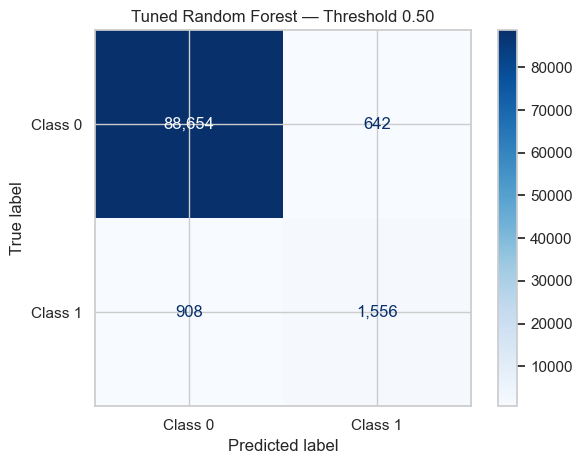

In [38]:
# Cell 6: Evaluate tuned Random Forest

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Test probabilities and default-threshold predictions
y_test_prob_tuned = best_rf_pipeline.predict_proba(X_test)[:, 1]
y_test_pred_tuned = (y_test_prob_tuned >= 0.50).astype(int)

print("Tuned Random Forest — threshold 0.50")
print("Accuracy:", round(accuracy_score(y_test, y_test_pred_tuned), 4))
print("Precision:", round(precision_score(y_test, y_test_pred_tuned, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_test_pred_tuned, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, y_test_pred_tuned, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_test_prob_tuned), 4))
print("PR-AUC:", round(average_precision_score(y_test, y_test_prob_tuned), 4))

print("\nClassification report:")
print(classification_report(y_test, y_test_pred_tuned, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred_tuned,
    display_labels=["Class 0", "Class 1"],
    cmap="Blues",
    values_format=","
)

plt.title("Tuned Random Forest — Threshold 0.50")
plt.tight_layout()
plt.show()

In [39]:
# Cell 7: Threshold tuning on a validation set

from sklearn.metrics import precision_score, recall_score, f1_score

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    stratify=y_train,
    random_state=RANDOM_STATE
)

# Train the selected configuration on the fitting partition
# This is a separate fit because threshold selection needs
# predictions from data not used to fit this model.

threshold_pipeline = ImbPipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("classifier", RandomForestClassifier(
        **{
            k.replace("classifier__", ""): v
            for k, v in rf_search.best_params_.items()
            if k.startswith("classifier__")
        },
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

threshold_pipeline.fit(X_fit, y_fit)

val_prob = threshold_pipeline.predict_proba(X_val)[:, 1]

threshold_results = []

for threshold in np.arange(0.30, 0.81, 0.05):
    val_pred = (val_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(y_val, val_pred, zero_division=0),
        "Recall": recall_score(y_val, val_pred, zero_division=0),
        "F1 Score": f1_score(y_val, val_pred, zero_division=0)
    })

threshold_results_df = pd.DataFrame(threshold_results).sort_values(
    "F1 Score", ascending=False
)

display(threshold_results_df)

best_threshold = threshold_results_df.iloc[0]["Threshold"]

print("Best validation threshold:", best_threshold)

,Threshold,Precision,Recall,F1 Score
6,0.60,0.788723,0.617453,0.692658
5,0.55,0.747630,0.640284,0.689806
4,0.50,0.709071,0.670218,0.689098
7,0.65,0.823022,0.580416,0.680750
3,0.45,0.666179,0.693557,0.679592
2,0.40,0.615920,0.718417,0.663232
8,0.70,0.852446,0.539320,0.660659
1,0.35,0.564915,0.741755,0.641369
9,0.75,0.883094,0.498224,0.637042
10,0.80,0.906250,0.456114,0.606817


Best validation threshold: 0.6


Tuned Random Forest + SMOTE
Threshold: 0.6
Accuracy: 0.9852
Precision: 0.7858
Recall: 0.6149
F1-score: 0.6899
ROC-AUC: 0.9564
PR-AUC: 0.7203

Classification report:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99     89296
           1       0.79      0.61      0.69      2464

    accuracy                           0.99     91760
   macro avg       0.89      0.81      0.84     91760
weighted avg       0.98      0.99      0.98     91760



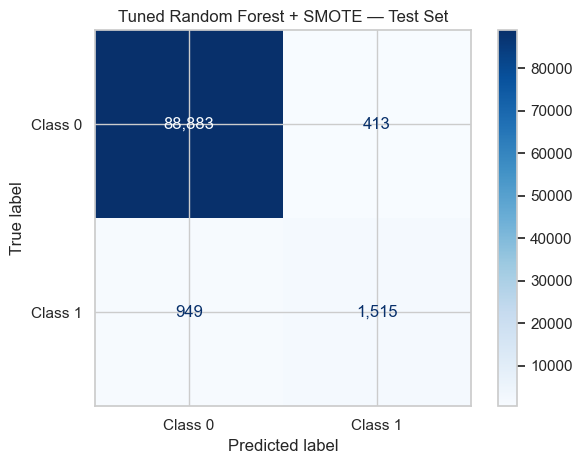

In [40]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)
import matplotlib.pyplot as plt

# Evaluate the tuned model on the untouched test set
final_threshold = 0.60

y_test_prob = threshold_pipeline.predict_proba(X_test)[:, 1]
y_test_pred = (y_test_prob >= final_threshold).astype(int)

print("Tuned Random Forest + SMOTE")
print("Threshold:", final_threshold)
print("Accuracy:", round(accuracy_score(y_test, y_test_pred), 4))
print("Precision:", round(
    precision_score(y_test, y_test_pred, zero_division=0), 4
))
print("Recall:", round(
    recall_score(y_test, y_test_pred, zero_division=0), 4
))
print("F1-score:", round(
    f1_score(y_test, y_test_pred, zero_division=0), 4
))
print("ROC-AUC:", round(roc_auc_score(y_test, y_test_prob), 4))
print("PR-AUC:", round(
    average_precision_score(y_test, y_test_prob), 4
))

print("\nClassification report:")
print(classification_report(
    y_test, y_test_pred, zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred,
    display_labels=["Class 0", "Class 1"],
    cmap="Blues",
    values_format=","
)

plt.title("Tuned Random Forest + SMOTE — Test Set")
plt.tight_layout()
plt.show()

In [41]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

threshold = 0.60

# Predictions from the existing tuned model
y_train_prob = threshold_pipeline.predict_proba(X_fit)[:, 1]
y_train_pred = (y_train_prob >= threshold).astype(int)

y_test_prob = threshold_pipeline.predict_proba(X_test)[:, 1]
y_test_pred = (y_test_prob >= threshold).astype(int)

comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision (Class 1)",
               "Recall (Class 1)", "F1-score (Class 1)"],
    "Training": [
        accuracy_score(y_fit, y_train_pred),
        precision_score(y_fit, y_train_pred, zero_division=0),
        recall_score(y_fit, y_train_pred, zero_division=0),
        f1_score(y_fit, y_train_pred, zero_division=0)
    ],
    "Test": [
        accuracy_score(y_test, y_test_pred),
        precision_score(y_test, y_test_pred, zero_division=0),
        recall_score(y_test, y_test_pred, zero_division=0),
        f1_score(y_test, y_test_pred, zero_division=0)
    ]
})

comparison["Absolute Gap"] = (
    comparison["Training"] - comparison["Test"]
).abs()

display(comparison.round(4))

,Metric,Training,Test,Absolute Gap
0,Accuracy,0.9884,0.9852,0.0032
1,Precision (Class 1),0.8625,0.7858,0.0767
2,Recall (Class 1),0.6751,0.6149,0.0603
3,F1-score (Class 1),0.7574,0.6899,0.0675


In [42]:
import pandas as pd
import numpy as np
from IPython.display import display

# Original model comparison results
final_results = results_df.copy()

# Rename columns if needed to match the final table
column_mapping = {
    "Precision (Class 1)": "Precision",
    "Recall (Class 1)": "Recall",
    "F1 Score (Class 1)": "F1 Score"
}

final_results = final_results.rename(columns=column_mapping)

# Keep only the required performance columns
required_cols = [
    "Model",
    "Train Accuracy",
    "Test Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC-AUC",
    "PR-AUC",
    "Overfitting (Y/N)"
]

final_results = final_results[
    [c for c in required_cols if c in final_results.columns]
].copy()

# Add the tuned Random Forest test results
tuned_rf_result = pd.DataFrame([{
    "Model": "Tuned Random Forest + SMOTE",
    "Train Accuracy": 0.9884,
    "Test Accuracy": 0.9852,
    "Precision": 0.7858,
    "Recall": 0.6149,
    "F1 Score": 0.6899,
    "ROC-AUC": 0.9564,
    "PR-AUC": 0.7203,
    "Overfitting (Y/N)": "Review F1 gap"
}])

# Combine original models and tuned Random Forest
final_results = pd.concat(
    [
        final_results[
            final_results["Model"] != "Tuned Random Forest + SMOTE"
        ],
        tuned_rf_result
    ],
    ignore_index=True
)

# Sort by F1 Score, highest first
final_results = final_results.sort_values(
    "F1 Score",
    ascending=False
).reset_index(drop=True)

display(final_results.round(4))

,Model,Train Accuracy,Test Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC,Overfitting (Y/N)
0,Tuned Random Forest + SMOTE,0.9884,0.9852,0.7858,0.6149,0.6899,0.9564,0.7203,Review F1 gap
1,Random Forest,0.9842,0.9813,0.6386,0.7013,0.6685,0.9572,0.7108,N
2,Decision Tree,0.9695,0.9679,0.4381,0.6985,0.5385,0.9152,0.5867,N
3,KNN,0.9998,0.9383,0.2654,0.7342,0.3899,0.8728,0.3338,Y
4,Extra Trees,0.9340,0.9322,0.2549,0.7922,0.3857,0.9426,0.6194,N
5,Logistic Regression,0.8641,0.8654,0.1478,0.8421,0.2514,0.9254,0.4642,N
6,Linear SVM,0.8388,0.8399,0.1272,0.8470,0.2213,0.9152,0.4139,N
7,Naive Bayes,0.4857,0.4873,0.0472,0.9436,0.0900,0.8803,0.3016,N


In [43]:
best_row = final_results.loc[
    final_results["F1 Score"].idxmax()
]

print("=" * 55)
print("FINAL BEST MODEL")
print("=" * 55)

print("Model:", best_row["Model"])
print("Test Accuracy:", f"{best_row['Test Accuracy']:.2%}")
print("Precision:", f"{best_row['Precision']:.2%}")
print("Recall:", f"{best_row['Recall']:.2%}")
print("F1 Score:", f"{best_row['F1 Score']:.2%}")
print("ROC-AUC:", f"{best_row['ROC-AUC']:.4f}")
print("PR-AUC:", f"{best_row['PR-AUC']:.4f}")
print("Overfitting assessment:", best_row["Overfitting (Y/N)"])

FINAL BEST MODEL
Model: Tuned Random Forest + SMOTE
Test Accuracy: 98.52%
Precision: 78.58%
Recall: 61.49%
F1 Score: 68.99%
ROC-AUC: 0.9564
PR-AUC: 0.7203
Overfitting assessment: Review F1 gap
